<sub>**The Annotated ML Handbook** · Part V: scikit-learn</sub>

# Chapter 19: Machine-learning concepts and the scikit-learn API

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/19-sklearn-concepts.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 19.1 The kinds of machine learning · *Beginner*

## 19.2 The workflow at a glance · *Beginner*

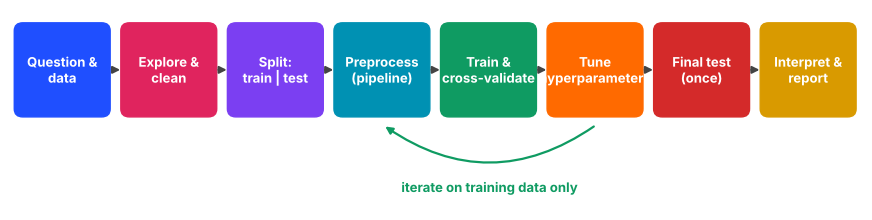

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
steps = [("Question &\ndata", "#1f4fff"), ("Explore &\nclean", "#e0245e"), ("Split:\ntrain | test", "#7b3ff2"),
         ("Preprocess\n(pipeline)", "#0091b3"), ("Train &\ncross-validate", "#0f9b62"), ("Tune\nhyperparameters", "#ff6a00"),
         ("Final test\n(once)", "#d42a2a"), ("Interpret &\nreport", "#d99a00")]
fig, ax = plt.subplots(figsize=(11, 2.6)); ax.set_xlim(0, 8); ax.set_ylim(-0.9, 1.1); ax.axis("off")
for i, (txt, c) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((i + 0.06, 0.05), 0.86, 0.9, boxstyle="round,pad=0.02,rounding_size=0.08", color=c))
    ax.text(i + 0.49, 0.5, txt, ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
    if i < 7: ax.annotate("", xy=(i + 1.06, 0.5), xytext=(i + 0.93, 0.5), arrowprops=dict(arrowstyle="-|>", color="#444", lw=1.5))
ax.annotate("", xy=(3.5, -0.05), xytext=(5.5, -0.05), arrowprops=dict(arrowstyle="-|>", color="#0f9b62", lw=1.6, connectionstyle="arc3,rad=-0.35"))
ax.text(4.5, -0.72, "iterate on training data only", ha="center", color="#0f9b62", fontsize=9.5, fontweight="bold")
plt.show()

## 19.3 The estimator API: fit, predict, transform · *Beginner*

**Your first model, end to end**

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True, as_frame=True)
print(X.shape, y.shape)
print(X.head(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("accuracy:", accuracy_score(y_test, y_pred))
print("same via .score:", model.score(X_test, y_test))
print(model.predict_proba(X_test.iloc[:3]).round(2))

(150, 4) (150,)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
accuracy: 0.9736842105263158
same via .score: 0.9736842105263158
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]]


**Five classifiers, one loop**

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=0),
    "RandomForest": RandomForestClassifier(random_state=0),
    "SVC": SVC(),
    "GaussianNB": GaussianNB(),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name:<20} test accuracy = {m.score(X_test, y_test):.3f}")

LogisticRegression   test accuracy = 0.947
DecisionTree         test accuracy = 0.921
RandomForest         test accuracy = 0.895
SVC                  test accuracy = 0.921
GaussianNB           test accuracy = 0.921


## 19.4 Baselines: is the model actually learning anything? · *Beginner*

**DummyClassifier and DummyRegressor**

In [5]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.datasets import load_diabetes

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("baseline accuracy:", round(base.score(X_test, y_test), 3))

Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, random_state=0)
print("mean-predictor R2:", round(DummyRegressor(strategy="mean").fit(Xd_tr, yd_tr).score(Xd_te, yd_te), 3))

baseline accuracy: 0.316
mean-predictor R2: -0.0


## 19.5 Overfitting, underfitting and the bias–variance trade-off · *Beginner*

**Polynomial degree controls flexibility**

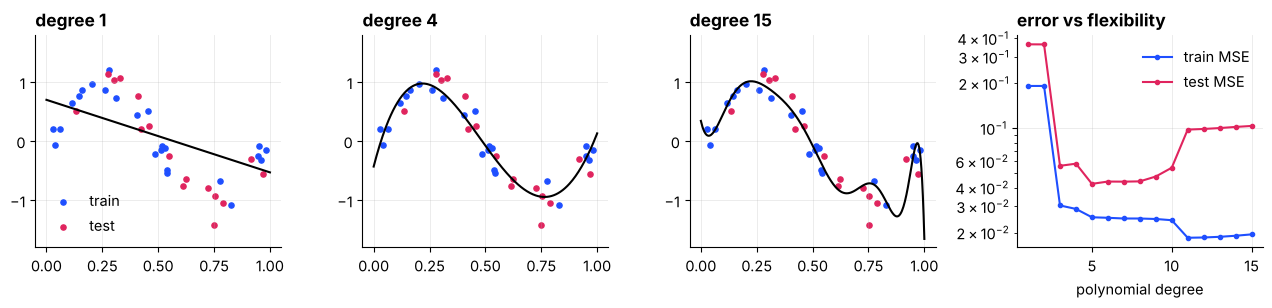

In [6]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 1, 40))
y_true = np.sin(2 * np.pi * x)
y = y_true + rng.normal(0, 0.25, x.size)
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.4, random_state=3)
grid = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, deg in zip(axes[:3], [1, 4, 15]):
    m = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    m.fit(x_tr.reshape(-1, 1), y_tr)
    ax.scatter(x_tr, y_tr, s=14, label="train"); ax.scatter(x_te, y_te, s=14, label="test")
    ax.plot(grid, m.predict(grid.reshape(-1, 1)), color="black")
    ax.set(ylim=(-1.8, 1.8), title=f"degree {deg}")
axes[0].legend(loc="lower left")

degrees = range(1, 16)
tr_err, te_err = [], []
for deg in degrees:
    m = make_pipeline(PolynomialFeatures(deg), LinearRegression()).fit(x_tr.reshape(-1, 1), y_tr)
    tr_err.append(mean_squared_error(y_tr, m.predict(x_tr.reshape(-1, 1))))
    te_err.append(mean_squared_error(y_te, m.predict(x_te.reshape(-1, 1))))
axes[3].plot(degrees, tr_err, marker="o", ms=3, label="train MSE")
axes[3].plot(degrees, te_err, marker="o", ms=3, label="test MSE")
axes[3].set(yscale="log", xlabel="polynomial degree", title="error vs flexibility")
axes[3].legend()
plt.tight_layout()
plt.show()

## 19.6 Why the test set is sacred · *Beginner*

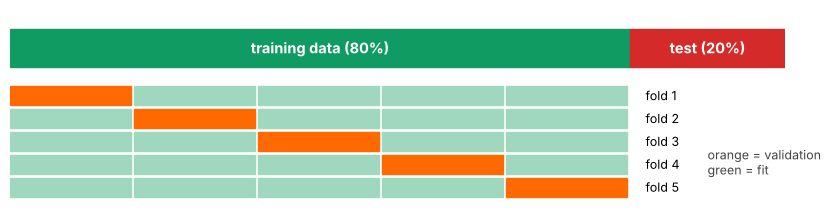

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 4.2); ax.axis("off")
ax.add_patch(plt.Rectangle((0, 3), 8, 0.8, color="#0f9b62")); ax.text(4, 3.4, "training data (80%)", ha="center", va="center", color="white", fontweight="bold")
ax.add_patch(plt.Rectangle((8, 3), 2, 0.8, color="#d42a2a")); ax.text(9, 3.4, "test (20%)", ha="center", va="center", color="white", fontweight="bold")
for k in range(5):
    y0 = 2.2 - k * 0.48
    for j in range(5):
        c = "#ff6a00" if j == k else "#9fd8bf"
        ax.add_patch(plt.Rectangle((j * 1.6, y0), 1.56, 0.4, color=c))
    ax.text(8.2, y0 + 0.2, f"fold {k + 1}", va="center", fontsize=9)
ax.text(9.0, 1.0, "orange = validation\ngreen = fit", fontsize=9, color="#444", va="center")
plt.show()

## 19.7 Reproducibility knobs · *Beginner*

## Try it yourself

1. Load `load_wine()` and compare `DummyClassifier`, `KNeighborsClassifier` and `RandomForestClassifier` on a stratified split.
2. In the polynomial demo, replace `LinearRegression` with `Ridge(alpha=1e-3)` for degree 15. What happens to the wiggles?
3. Re-run the iris example with five different `random_state` values. How much does test accuracy vary? (This is why we cross-validate.)

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 19*.